# Differentiation

Fraction of birds with isolated labels (nearest-neighbour Cohen's d > 3) for annotated and predicted labels. Note that with shuffled labels we don't find isolated labels; so those are not shown.

In [1]:
import sys
sys.path.append('../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pipeline.collect_metrics import load_metrics
from viz.stacked_bar import stacked_bars, nested_bar
from viz.utils import set_mpl_style
set_mpl_style()

from viz.rows import row_height_ratios, annotate_row_groups
from fig2_settings import SECTIONS, build_row_specs, ANNOT_CMAP, PRED_CMAP, LABEL_TYPE_NAMES

In [2]:
bird_metrics, _, _ = load_metrics()
row_specs = build_row_specs(SECTIONS)
ROW_HEIGHT_RATIOS = row_height_ratios(row_specs, header_ratio=0.12)

In [3]:
# Check that indeed shuffled labels are never isolated
shuffled_metrics = bird_metrics.query("label_type == 'shuffle'")
assert (shuffled_metrics['n_isolated_labels'] == 0).all()

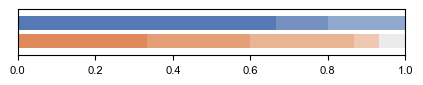

In [4]:
COUNT_THRESHOLDS = (1, 2, 3, 4)
SOURCE_NAMES = (LABEL_TYPE_NAMES['annot'], LABEL_TYPE_NAMES['pred'])

def plot_differentiation_ax(ax, datasets, rhythm_type, metrics, thresholds=COUNT_THRESHOLDS, annot_cmap=ANNOT_CMAP, pred_cmap=PRED_CMAP, bar_gap=0.2, bar_pad=0.0):
    annot = metrics.query(
        "dataset_id in @datasets and rhythm_type == @rhythm_type and label_type == 'annot'"
    )['n_isolated_labels']
    pred = metrics.query(
        "dataset_id in @datasets and rhythm_type == @rhythm_type and label_type == 'pred'"
    )['n_isolated_labels']
    sources = list(zip(SOURCE_NAMES, [annot, pred], [annot_cmap, pred_cmap]))

    data, note, bars = {}, {}, {}
    for name, n_isolated, cmap in sources:
        bars[name] = dict(cmap=cmap)
        if len(n_isolated) == 0:
            data[name] = None
            note[name] = f'no {name.lower()}'
        else:
            data[name] = [(n_isolated >= k).mean() for k in sorted(thresholds)]

    stacked_bars(ax, data, bars=bars, text=note, gap=bar_gap, pad=bar_pad)

plt.subplots(figsize=(5, 0.6))
plot_differentiation_ax(plt.gca(), ['ns'], 'syll_dur', bird_metrics, bar_pad=0.3)

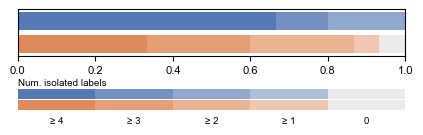

In [5]:
def differentiation_legend(
    ax, thresholds=COUNT_THRESHOLDS, annot_cmap=ANNOT_CMAP, pred_cmap=PRED_CMAP,
    loc='lower center', bbox_to_anchor=(0.5, -0.7), width=1.0, height=0.5, row_gap=0.15,
):
    
    ks = sorted(thresholds)
    n = len(ks)
    # Split [0, 1] in to n+1 equal width parts
    bounds = np.arange(n, 0, -1) / (n + 1)

    x, y = bbox_to_anchor
    x0 = x - width / 2 if 'center' in loc else x
    cbar_ax = ax.inset_axes([x0, y - height, width, height], transform=ax.transAxes)
    nested_bar(cbar_ax, bounds, cmap=annot_cmap, y=0.25, height=0.5 - row_gap / 2)
    nested_bar(cbar_ax, bounds, cmap=pred_cmap, y=0.75, height=0.5 - row_gap / 2)

    # Ticks centered under each segment (between consecutive edges), not
    # on the boundary lines themselves.
    edges = np.concatenate([[0], bounds[::-1], [1]])
    centers = (edges[:-1] + edges[1:]) / 2
    labels = [f'≥ {k}' for k in ks[::-1]] + ['0']

    cbar_ax.set_xlim(0, 1)
    cbar_ax.set_ylim(1, 0)
    cbar_ax.set_xticks(centers)
    cbar_ax.set_xticklabels(labels, fontsize=7)
    cbar_ax.tick_params(length=0)
    cbar_ax.set_yticks([])
    cbar_ax.set_title('Num. isolated labels', fontsize=7, pad=2, ha='left', x=0)
    for spine in cbar_ax.spines.values():
        spine.set_visible(False)

plt.subplots(figsize=(5, 0.6))
plot_differentiation_ax(plt.gca(), ['ns'], 'syll_dur', bird_metrics)
differentiation_legend(plt.gca())

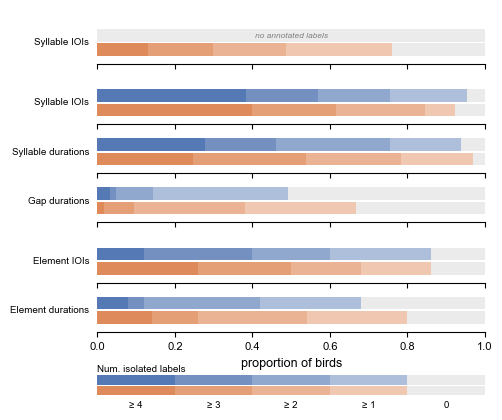

In [6]:
def plot_differentiation_column(
    axes, row_specs, metrics, thresholds=COUNT_THRESHOLDS, annot_cmap=ANNOT_CMAP, pred_cmap=PRED_CMAP,
    show_row_labels=True, legend=True, bar_gap=0.1, bar_pad=0.0,
    legend_loc='lower center', legend_bbox_to_anchor=(0.5, -1), legend_ax='last',
):
    first_data_ax, last_data_ax = None, None
    for ax, (kind, row_label, spec) in zip(axes, row_specs):
        if kind == 'header':
            ax.axis('off')
            continue
        datasets, rhythm_type = spec
        plot_differentiation_ax(ax, datasets, rhythm_type, metrics, thresholds=thresholds, annot_cmap=annot_cmap, pred_cmap=pred_cmap, bar_gap=bar_gap, bar_pad=bar_pad)
        first_data_ax = first_data_ax or ax
        last_data_ax = ax
        if show_row_labels:
            ax.set_ylabel(row_label, rotation=0, ha='right', va='center', fontsize=7, labelpad=6)
    if legend and first_data_ax is not None:
        anchor_ax = first_data_ax if legend_ax == 'first' else last_data_ax
        differentiation_legend(
            anchor_ax, thresholds=thresholds,
            loc=legend_loc, bbox_to_anchor=legend_bbox_to_anchor,
        )
    return axes

fig, axes = plt.subplots(
    len(row_specs), 1, figsize=(5, 0.5 * sum(ROW_HEIGHT_RATIOS) + 1),
    gridspec_kw=dict(height_ratios=ROW_HEIGHT_RATIOS), sharex=True,
)
plot_differentiation_column(axes, row_specs, bird_metrics, bar_pad=0.5)

axes[-1].set_xlabel('proportion of birds')
sns.despine(left=True)